In [1]:
import sys
sys.path.append("..")

In [7]:
import torch
import torch.nn.functional as F
from src.vgg import VGGFeatures
from src.image_utils import load_image
from src.losses import gram_matrix, style_grams, style_loss, content_loss

In [8]:
device = "cuda"
style = load_image("../data/style/starry_night.jpg", 384, device)
content = load_image("../data/content/Abyssinian_24.jpg", 384, device)

In [4]:
extractor = VGGFeatures().to(device)
layers = ["conv1_1", "conv2_1", "conv3_1", "conv4_1", "conv5_1"]

In [16]:
with torch.no_grad():
    content_target = extractor(content)["conv4_2"]
    style_feats = extractor(style)
    target_grams = {k: v.detach() for k, v in style_grams(style_feats).items()}

In [21]:
image = content.clone().requires_grad_(True)
content_weight = 1
style_weight = 1e4

In [22]:
optimiser = torch.optim.Adam([image], lr=0.02)

In [23]:
for i in range(501):
    features = extractor(image)
    c = content_loss(features["conv4_2"], content_target)
    s = style_loss(features, target_grams)
    total = content_weight * c + style_weight * s
    optimiser.zero_grad()
    total.backward()
    optimiser.step()

    with torch.no_grad():
        image.clamp_(0,1)

    if i % 100 == 0:
        print(f"Iteration {i}: c_loss = {c.item():.4f}")
        print(f"Iteration {i}: s_loss = {s.item():.4f}")
        print(f"Iteration {i}: total_loss = {total.item():.4f}")

Iteration 0: c_loss = 0.0000
Iteration 0: s_loss = 0.0483
Iteration 0: total_loss = 483.1177
Iteration 100: c_loss = 14.9823
Iteration 100: s_loss = 0.0014
Iteration 100: total_loss = 29.3643
Iteration 200: c_loss = 12.9581
Iteration 200: s_loss = 0.0009
Iteration 200: total_loss = 22.0489
Iteration 300: c_loss = 11.1612
Iteration 300: s_loss = 0.0008
Iteration 300: total_loss = 19.3852
Iteration 400: c_loss = 10.2887
Iteration 400: s_loss = 0.0008
Iteration 400: total_loss = 17.9981
Iteration 500: c_loss = 10.0611
Iteration 500: s_loss = 0.0007
Iteration 500: total_loss = 16.8153


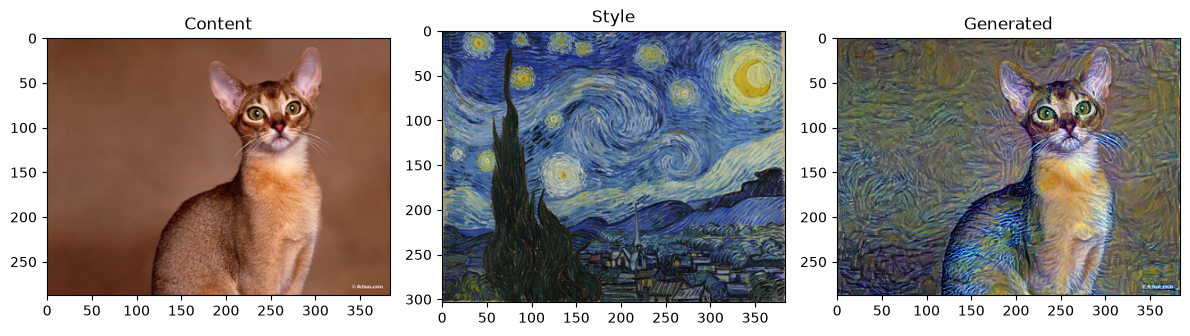

In [20]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(12, 6))

ax[0].set_title("Content")
ax[0].imshow(content.detach().cpu().squeeze(0).permute(1,2,0).numpy())
ax[1].set_title("Style")
ax[1].imshow(style.detach().cpu().squeeze(0).permute(1,2,0).numpy())
ax[2].set_title("Generated")
ax[2].imshow(image.detach().cpu().squeeze(0).permute(1,2,0).numpy())
fig.tight_layout()
fig.savefig("../outputs/stylised_cat_starry.jpg")

In [24]:
from src.image_utils import save_image
save_image(image, "../outputs/compare_cat_starry.jpg")

In [5]:
import matplotlib.pyplot as plt
from src.style_transfer import run_style_transfer
from src.image_utils import save_image

def to_img(t):
    return t.detach().cpu().squeeze(0).permute(1, 2, 0).numpy()

out_1e4, hist_1e4 = run_style_transfer(extractor, content, style, style_weight=1e4)
save_image(out_1e4, "../outputs/stylised_cat_starry.png")

out_1e5, hist_1e5 = run_style_transfer(extractor, content, style, style_weight=1e5)
save_image(out_1e5, "../outputs/stylised_cat_starry_1e5.png")

print("1e4 final: c=%.4f  s=%.6f" % hist_1e4[-1][1:3])
print("1e5 final: c=%.4f  s=%.6f" % hist_1e5[-1][1:3])

step 0: c=0.0000  s=0.0483  total=483.1177
step 100: c=14.9720  s=0.0014  total=29.3682
step 200: c=12.5296  s=0.0009  total=21.8656
step 300: c=11.5413  s=0.0008  total=19.8311
step 400: c=10.3595  s=0.0007  total=17.4446
step 500: c=10.0401  s=0.0007  total=16.8581
step 0: c=0.0000  s=0.0483  total=4831.1768
step 100: c=41.2304  s=0.0010  total=137.7070
step 200: c=36.2935  s=0.0004  total=80.8048
step 300: c=33.7193  s=0.0003  total=62.7975
step 400: c=31.5203  s=0.0002  total=55.9404
step 500: c=30.4232  s=0.0002  total=50.7802
1e4 final: c=10.0401  s=0.000682
1e5 final: c=30.4232  s=0.000204


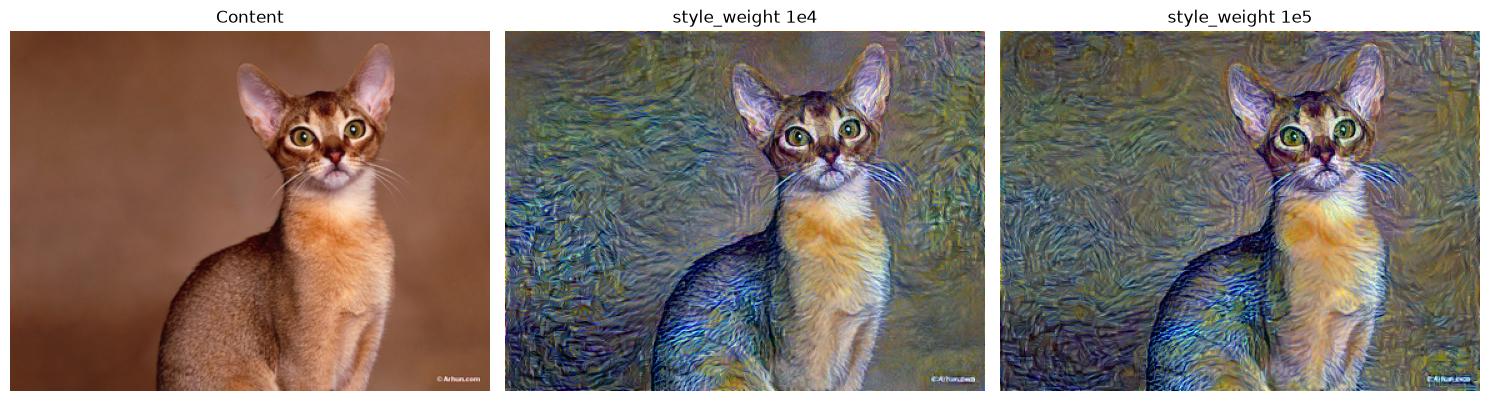

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, img, title in zip(ax, [content, out_1e4, out_1e5],
                         ["Content", "style_weight 1e4", "style_weight 1e5"]):
    a.imshow(to_img(img))
    a.set_title(title)
    a.axis("off")
plt.tight_layout()
fig.savefig("../outputs/compare_cat_starry.png", dpi=150)
plt.show()

In [1]:
import sys
sys.path.append("..")

In [2]:
from src.losses import total_variation_loss
import torch

x = torch.tensor([[1., 3., 2.], [0., 2., 4.]]).reshape(1,1,2,3)
loss = total_variation_loss(x)
loss.item()

3.0833334922790527

In [3]:
x = torch.ones(1,3,64,64)
loss = total_variation_loss(x)
loss.item()

0.0

In [6]:
x = torch.rand(1,3,64,64)
loss = total_variation_loss(x)
loss.item()

0.6664550304412842

In [11]:
noise = torch.rand(1, 3, 64, 64)
photo_small = F.interpolate(content.detach().cpu(), size=(64, 64),
                            mode="bilinear", align_corners=False)
print("noise TV =", round(total_variation_loss(noise).item(), 4))
print("photo TV =", round(total_variation_loss(photo_small).item(), 4))

noise TV = 0.671
photo TV = 0.0612


In [10]:
img = torch.rand(1, 3, 64, 64, requires_grad=True)
total_variation_loss(img).backward()
print("grad sum =", img.grad.abs().sum().item())

grad sum = 2.4102180004119873


In [1]:
import sys
sys.path.append("..")

In [3]:
from src.vgg import VGGFeatures
from src.image_utils import load_image

device = "cuda"
style = load_image("../data/style/starry_night.jpg", 384, device)
content = load_image("../data/content/Abyssinian_24.jpg", 384, device)
extractor = VGGFeatures().to(device)

In [5]:
from src.style_transfer import run_style_transfer
from src.image_utils import save_image

for i in [0,10,100,1000]:
    out, hist = run_style_transfer(extractor, content, style, style_weight=1e4, tv_weight=i)
    save_image(out, f"../outputs/tv_weight_{i}.png")

step 0: c=0.0000  s=0.0483  total=483.1177  tv=0.0303
step 100: c=14.7698  s=0.0015  total=29.6632  tv=0.1450
step 200: c=12.6621  s=0.0009  total=21.7381  tv=0.1524
step 300: c=11.2591  s=0.0008  total=18.9533  tv=0.1590
step 400: c=10.4074  s=0.0007  total=17.4280  tv=0.1635
step 500: c=9.6139  s=0.0007  total=16.8315  tv=0.1670
step 0: c=0.0000  s=0.0483  total=483.4210  tv=0.0303
step 100: c=14.8777  s=0.0014  total=30.6634  tv=0.1386
step 200: c=12.8512  s=0.0009  total=23.4601  tv=0.1356
step 300: c=10.8481  s=0.0008  total=20.3006  tv=0.1322
step 400: c=10.1426  s=0.0008  total=19.0478  tv=0.1272
step 500: c=10.0240  s=0.0007  total=18.0457  tv=0.1231
step 0: c=0.0000  s=0.0483  total=486.1509  tv=0.0303
step 100: c=15.3972  s=0.0014  total=39.8209  tv=0.1034
step 200: c=12.5060  s=0.0011  total=32.1195  tv=0.0873
step 300: c=11.5059  s=0.0009  total=28.1623  tv=0.0810
step 400: c=11.3015  s=0.0008  total=27.4805  tv=0.0808
step 500: c=9.7227  s=0.0009  total=26.0619  tv=0.0760


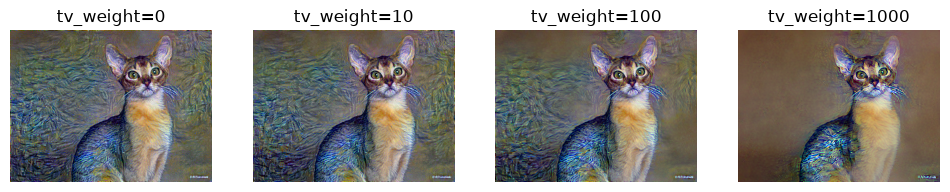

In [8]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,4, figsize=(12,4))

for i,tv in enumerate([0,10,100,1000]):
    img = load_image(f"../outputs/tv_weight_{tv}.png", 384, device)
    ax[i].imshow(img.detach().cpu().squeeze(0).permute(1,2,0).numpy())
    ax[i].set_title(f"tv_weight={tv}")
    ax[i].axis("off")
plt.show()